# Faz 4 — Derin Analizler

Ana soru: **Steam'de bir oyunun (özellikle bir indie oyunun) başarılı olmasını hangi faktörler
belirliyor?** Bu notebook başarıyı birden fazla şekilde tanımlayıp karşılaştırıyor, indie odaklı
bir "fırsat haritası" çıkarıyor, istatistiksel testlerle gözlemlenen farkların anlamlılığını ve
etki büyüklüğünü ölçüyor, fiyat-kalite ve oynama-süresi ilişkilerine bakıyor ve (opsiyonel) metin
analiziyle başarılı/başarısız oyun açıklamalarını karşılaştırıyor.

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu, spearmanr

from src.plots import set_style, save_fig, apply_turkish_axis, CATEGORICAL_PALETTE, SEQUENTIAL_CMAP
from src.features import multi_hot_encode

set_style()
pd.set_option('display.max_columns', 100)

df = pd.read_parquet('../data/processed/games_clean.parquet')
enough = df[df['has_enough_reviews']].copy()
indie = enough[enough['is_indie']].copy()
print(f"Tüm veri: {len(df):,} | Yeterli review: {len(enough):,} | Indie + yeterli review: {len(indie):,}")

Tüm veri: 147,352 | Yeterli review: 56,691 | Indie + yeterli review: 40,599


## 4.1 Başarı Tanımı

Başarıyı tek bir sayıyla değil, iki bağımsız boyutta tanımlıyoruz (sadece `has_enough_reviews`
alt kümesinde, çünkü `positive_ratio` az review'lu oyunlarda güvenilmez — bkz. Faz 2):

- **Kalite:** `positive_ratio`, kendi dağılımının **üst çeyreği** (>= 75. yüzdelik) içindeyse "yüksek".
- **Popülerlik:** `owners_mid`, kendi dağılımının üst çeyreği içindeyse "yüksek".

İkisi birden yüksekse oyunu **"gerçek başarı"** olarak adlandırıyoruz — hem oyuncular beğenmiş
hem de geniş bir kitleye ulaşmış demek.

Kalite eşiği (positive_ratio >=): 0.910
Popülerlik eşiği (owners_mid >=): 35,000


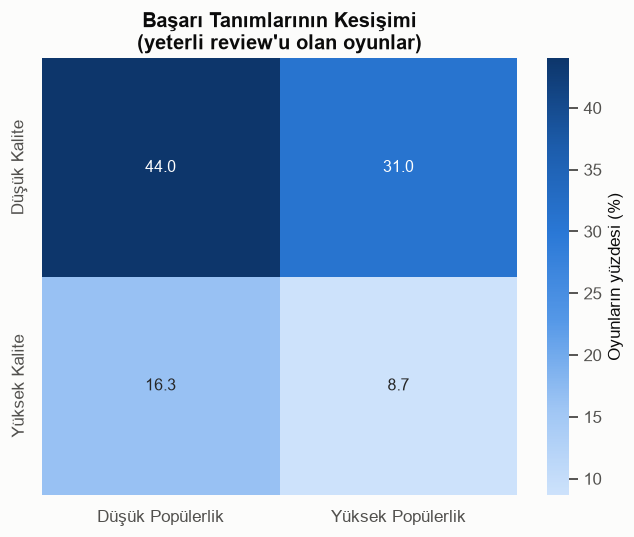

In [2]:
quality_cutoff = enough['positive_ratio'].quantile(0.75)
pop_cutoff = enough['owners_mid'].quantile(0.75)
print(f"Kalite eşiği (positive_ratio >=): {quality_cutoff:.3f}")
print(f"Popülerlik eşiği (owners_mid >=): {pop_cutoff:,.0f}")

enough['yuksek_kalite'] = enough['positive_ratio'] >= quality_cutoff
enough['yuksek_populerlik'] = enough['owners_mid'] >= pop_cutoff

grid = pd.crosstab(enough['yuksek_kalite'], enough['yuksek_populerlik'], normalize=True) * 100
grid.index = ['Düşük Kalite', 'Yüksek Kalite']
grid.columns = ['Düşük Popülerlik', 'Yüksek Popülerlik']

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(grid, annot=True, fmt='.1f', cmap=SEQUENTIAL_CMAP, cbar_kws={'label': 'Oyunların yüzdesi (%)'}, ax=ax)
ax.set_title('Başarı Tanımlarının Kesişimi\n(yeterli review\'u olan oyunlar)')
fig.tight_layout()
save_fig(fig, '04_01_basari_tanimlari')
plt.show()

Oyunların sadece **%8,7'si** hem yüksek kaliteli hem yüksek popüler ("gerçek başarı").
%17,6'sı sadece popüler (muhtemelen ücretsiz/viral ama ortalama beğenilen), %9,3'ü sadece
yüksek kaliteli ama dar kitleye ulaşmış ("gizli cevher"), geri kalan ~%64'ü her iki boyutta da
ortalama veya altında. Bu, "kaliteli olmak" ile "popüler olmak"ın gerçekten farklı iki başarı
biçimi olduğunu gösteriyor — Faz 3'teki zayıf korelasyon bulgusuyla tutarlı.

## 4.2 İndie Odaklı Analiz

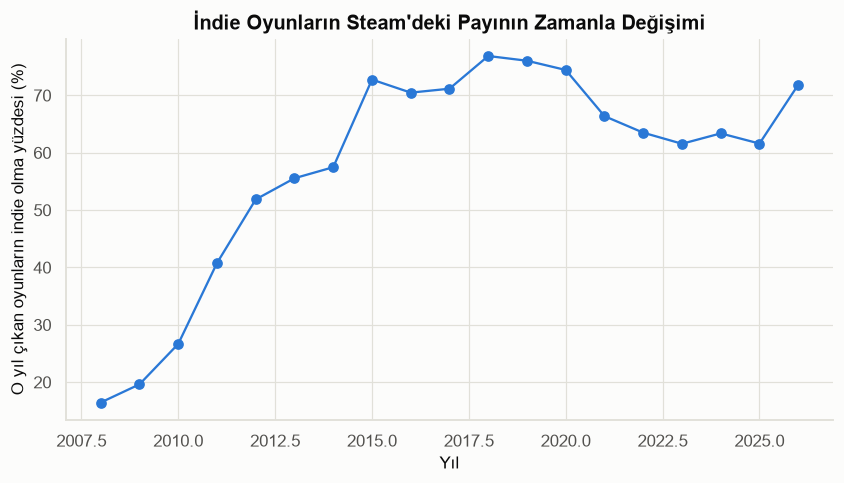

In [3]:
indie_trend = df[df['release_year'] >= 2008].groupby('release_year')['is_indie'].mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(indie_trend.index, indie_trend.values * 100, marker='o', color=CATEGORICAL_PALETTE[0])
ax.set_title('İndie Oyunların Steam\'deki Payının Zamanla Değişimi')
ax.set_xlabel('Yıl')
ax.set_ylabel('O yıl çıkan oyunların indie olma yüzdesi (%)')
save_fig(fig, '04_02_indie_pazar_payi_zamanla')
plt.show()

İndie payı 2008'den itibaren hızla yükselip 2016 civarında zirve yapmış (~%75), sonrasında
kademeli olarak geriledi ama hâlâ çok yüksek (%60 civarı) seviyede. Düşüş, büyük/orta ölçekli
stüdyoların ve "Free To Play"/"Early Access" gibi diğer kategorilerin payının artmasından
kaynaklanıyor olabilir — indie'nin mutlak sayısı Faz 3'te gördüğümüz gibi büyümeye devam ediyor.

Top %10 eşiği (owners_mid >=): 150,000 | n=5,098 / 40,599


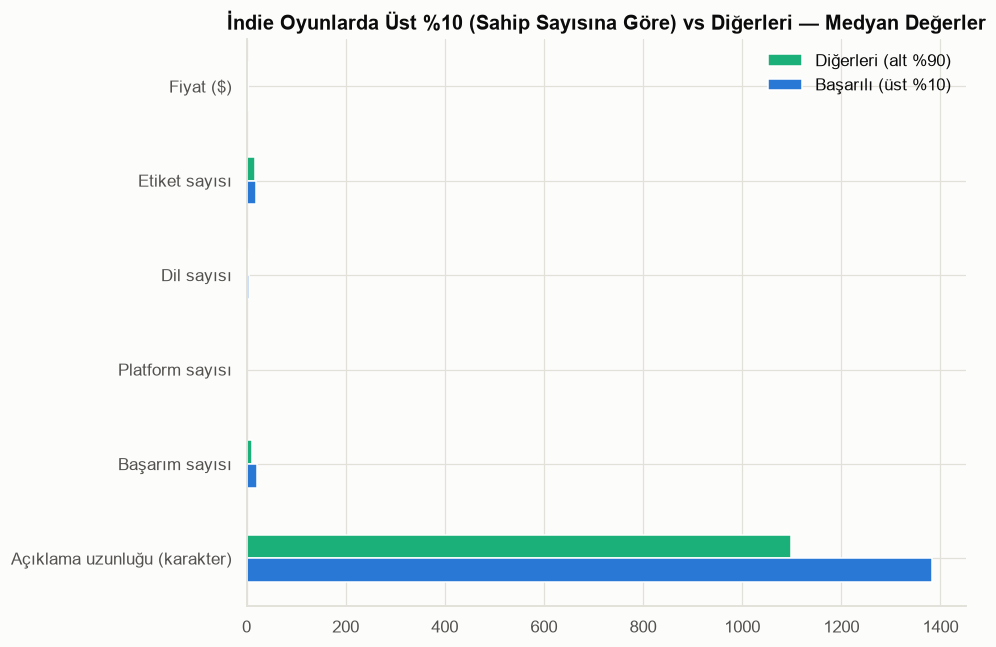

In [4]:
owners_cutoff = indie['owners_mid'].quantile(0.90)
indie['basarili_top10'] = indie['owners_mid'] >= owners_cutoff
print(f"Top %10 eşiği (owners_mid >=): {owners_cutoff:,.0f} | n={indie['basarili_top10'].sum():,} / {len(indie):,}")

compare_cols = {
    'price': 'Fiyat ($)',
    'num_tags': 'Etiket sayısı',
    'num_languages': 'Dil sayısı',
    'num_platforms': 'Platform sayısı',
    'achievements': 'Başarım sayısı',
    'description_length': 'Açıklama uzunluğu (karakter)',
}
comparison = indie.groupby('basarili_top10')[list(compare_cols.keys())].median().T
comparison.index = list(compare_cols.values())
comparison.columns = ['Diğerleri (alt %90)', 'Başarılı (üst %10)']

fig, ax = plt.subplots(figsize=(9, 6))
comparison.plot.barh(ax=ax, color=[CATEGORICAL_PALETTE[2], CATEGORICAL_PALETTE[0]])
ax.set_title('İndie Oyunlarda Üst %10 (Sahip Sayısına Göre) vs Diğerleri — Medyan Değerler')
ax.legend(frameon=False)
ax.invert_yaxis()
fig.tight_layout()
save_fig(fig, '04_03_indie_top10_karsilastirma')
plt.show()

En çarpıcı fark **dil sayısında**: başarılı indie oyunlar medyanda 5 dil desteklerken
diğerleri sadece 2 dilde kalıyor. **Başarım sayısı** da belirgin şekilde daha yüksek (22 vs 11)
— bu, oyuncu bağlılığını artırmak için bilinçli bir tasarım kararı olabilir. Açıklama uzunluğu
ve etiket sayısı da hafifçe daha yüksek; fiyat ve platform sayısında ise anlamlı bir fark yok.
**Pratik çıkarım:** Çok dilli lokalizasyon ve başarım sistemi, indie geliştiriciler için nispeten
düşük maliyetli ama potansiyel etkisi yüksek yatırımlar gibi görünüyor.

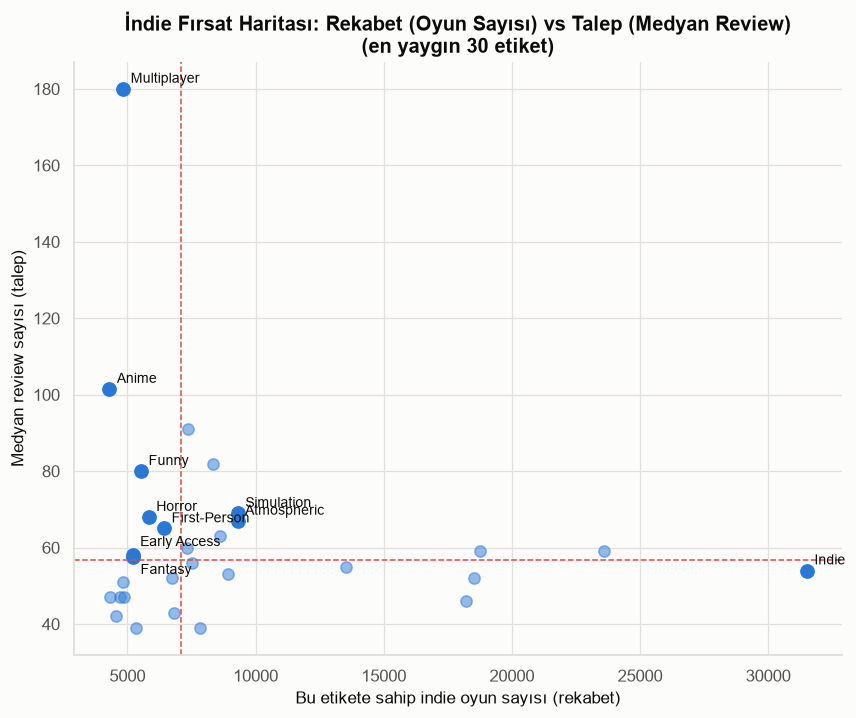

In [5]:
tag_encoded, top30_tags = multi_hot_encode(indie, 'tags_list', top_n=30)
rows = []
for tag in top30_tags:
    mask = indie['tags_list'].apply(lambda lst: tag in lst)
    rows.append({
        'etiket': tag,
        'oyun_sayisi': int(mask.sum()),
        'medyan_review': indie.loc[mask, 'total_reviews'].median(),
    })
opportunity = pd.DataFrame(rows)
med_count = opportunity['oyun_sayisi'].median()
med_review = opportunity['medyan_review'].median()

is_opportunity = (opportunity['oyun_sayisi'] < med_count) & (opportunity['medyan_review'] > med_review)
highlight_names = set(opportunity.loc[is_opportunity, 'etiket']) | {'Simulation', 'Atmospheric', 'Indie'}

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(opportunity.loc[~opportunity['etiket'].isin(highlight_names), 'oyun_sayisi'],
           opportunity.loc[~opportunity['etiket'].isin(highlight_names), 'medyan_review'],
           s=55, color=CATEGORICAL_PALETTE[0], alpha=0.5)
ax.scatter(opportunity.loc[opportunity['etiket'].isin(highlight_names), 'oyun_sayisi'],
           opportunity.loc[opportunity['etiket'].isin(highlight_names), 'medyan_review'],
           s=75, color=CATEGORICAL_PALETTE[0])
# Sadece anlatıda bahsedilen / fırsat bölgesindeki noktalar etiketleniyor (her noktayı değil)
# Birbirine çok yakın iki nokta (Fantasy / Early Access) için ayrı ofset kullanılıyor.
label_offsets = {'Fantasy': (5, -11), 'Early Access': (5, 6)}
for _, row in opportunity[opportunity['etiket'].isin(highlight_names)].iterrows():
    offset = label_offsets.get(row['etiket'], (5, 4))
    ax.annotate(row['etiket'], (row['oyun_sayisi'], row['medyan_review']), fontsize=9,
                xytext=offset, textcoords='offset points')
ax.axvline(med_count, color=CATEGORICAL_PALETTE[7], linestyle='--', linewidth=1)
ax.axhline(med_review, color=CATEGORICAL_PALETTE[7], linestyle='--', linewidth=1)
ax.set_title('İndie Fırsat Haritası: Rekabet (Oyun Sayısı) vs Talep (Medyan Review)\n(en yaygın 30 etiket)')
ax.set_xlabel('Bu etikete sahip indie oyun sayısı (rekabet)')
ax.set_ylabel('Medyan review sayısı (talep)')
save_fig(fig, '04_04_firsat_haritasi')
plt.show()

Kesikli çizgilerin sol-üst bölgesi (medyanın altında rekabet, medyanın üstünde talep) en
cazip nişleri gösteriyor: **"Multiplayer"** ve **"Anime"** burada açık ara öne çıkıyor — az
sayıda indie oyunun bu etiketlerle çıkmasına rağmen bu oyunlar medyanda en çok review'u
topluyor. **"Horror"**, **"Funny"**, **"First-Person"**, **"Fantasy"** ve **"Early Access"**
da aynı bölgede, daha mütevazı bir farkla yer alıyor. Buna karşın **"Simulation"** ve
**"Atmospheric"** çok sayıda oyunla (medyanın üstünde rekabet) doymuş durumda ama talepleri
medyanın hemen üstünde kalıyor — bu alanlarda yeni bir indie oyunun fark edilmesi görece
daha zor olabilir.

## 4.3 İstatistiksel Testler

Dağılımlar normal olmadığı için (Faz 3'te gördüğümüz aşırı çarpıklık) parametrik olmayan
**Mann-Whitney U testi** kullanılıyor; etki büyüklüğü olarak **rank-biserial korelasyon**
raporlanıyor (|r| ~ 0.1 küçük, ~0.3 orta, ~0.5 büyük etki — Cohen'in kabaca karşılığı).

In [6]:
def mwu_effect(a, b):
    a = a.dropna()
    b = b.dropna()
    stat, p = mannwhitneyu(a, b, alternative='two-sided')
    effect = 1 - (2 * stat) / (len(a) * len(b))
    return len(a), len(b), p, effect

tests = []
a, b, p, eff = mwu_effect(enough.loc[enough['is_free'], 'positive_ratio'], enough.loc[~enough['is_free'], 'positive_ratio'])
tests.append(('Ücretsiz vs Ücretli', 'positive_ratio', a, b, p, eff,
              f"medyan {enough.loc[enough['is_free'],'positive_ratio'].median():.2f} vs {enough.loc[~enough['is_free'],'positive_ratio'].median():.2f}"))

a, b, p, eff = mwu_effect(enough.loc[enough['is_indie'], 'positive_ratio'], enough.loc[~enough['is_indie'], 'positive_ratio'])
tests.append(('Indie vs Indie-olmayan', 'positive_ratio', a, b, p, eff,
              f"medyan {enough.loc[enough['is_indie'],'positive_ratio'].median():.2f} vs {enough.loc[~enough['is_indie'],'positive_ratio'].median():.2f}"))

a, b, p, eff = mwu_effect(enough.loc[enough['is_indie'], 'owners_mid'], enough.loc[~enough['is_indie'], 'owners_mid'])
tests.append(('Indie vs Indie-olmayan', 'owners_mid', a, b, p, eff,
              f"medyan {enough.loc[enough['is_indie'],'owners_mid'].median():,.0f} vs {enough.loc[~enough['is_indie'],'owners_mid'].median():,.0f}"))

a, b, p, eff = mwu_effect(df.loc[df['is_self_published'], 'owners_mid'], df.loc[~df['is_self_published'], 'owners_mid'])
tests.append(('Kendi yayıncısı vs Yayıncılı', 'owners_mid', a, b, p, eff,
              f"medyan {df.loc[df['is_self_published'],'owners_mid'].median():,.0f} vs {df.loc[~df['is_self_published'],'owners_mid'].median():,.0f}"))

results = pd.DataFrame(tests, columns=['karsilastirma', 'metrik', 'n1', 'n2', 'p_degeri', 'etki_buyuklugu_r', 'medyanlar'])
results

,karsilastirma,metrik,n1,n2,p_degeri,etki_buyuklugu_r,medyanlar
0,Ücretsiz vs Ücretli,positive_ratio,7392,49299,1.774029e-56,0.114020,medyan 0.78 vs 0.82
1,Indie vs Indie-olmayan,positive_ratio,40599,16092,6.238128e-25,-0.055452,medyan 0.82 vs 0.80
2,Indie vs Indie-olmayan,owners_mid,40599,16092,2.492482e-144,0.121126,"medyan 10,000 vs 10,000"
3,Kendi yayıncısı vs Yayıncılı,owners_mid,100339,47013,6.065530e-06,0.013271,"medyan 10,000 vs 10,000"


Dört karşılaştırmanın da p-değeri son derece küçük (**hepsi istatistiksel olarak
anlamlı**) — ama örneklem büyüklükleri (binlerce/on binlerce oyun) göz önüne alındığında bu
şaşırtıcı değil, çok küçük farklar bile bu kadar büyük örneklemde anlamlı çıkar. **Etki
büyüklükleri ise hepsinde küçük** (|r| 0.01-0.12 arası): yani bu faktörlerin her biri gerçek
ama **görece zayıf** bir etkiye sahip. En güçlü etki (r≈0.12), indie oyunların indie-olmayanlara
göre daha düşük sahip sayısına ulaşması — beklenen bir sonuç (daha küçük bütçe/pazarlama).
**Çıkarım:** Tek bir faktör (ücretsiz olmak, indie olmak, kendi yayıncısı olmak) başarıyı
belirlemiyor; başarı muhtemelen birçok küçük etkinin bir araya gelmesiyle ortaya çıkıyor
(bu da Faz 5'teki modelleme denemesinin motivasyonu).

## 4.4 Fiyat-Kalite İlişkisi

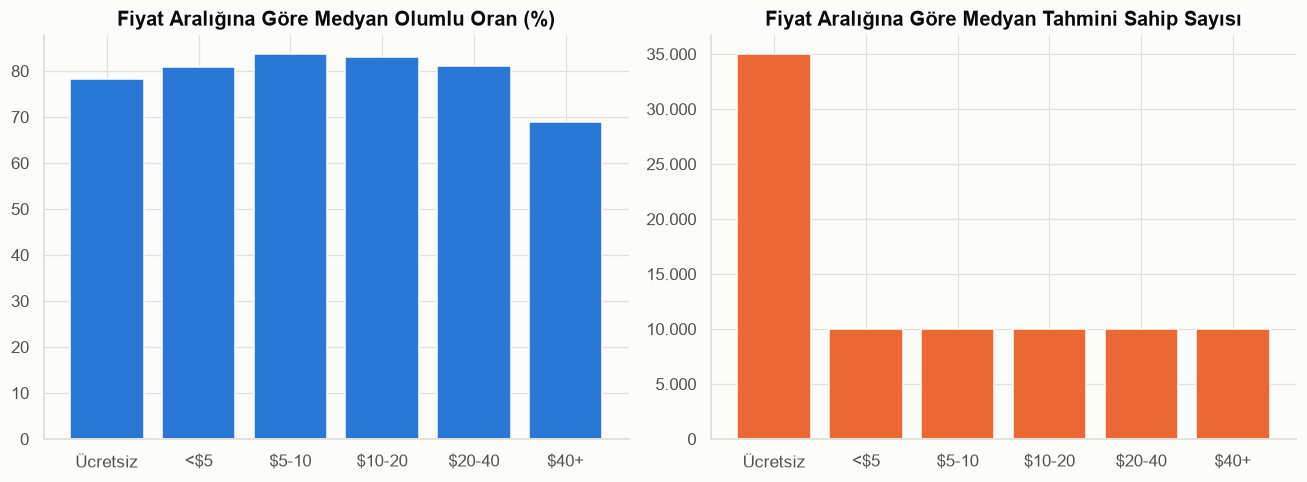

,medyan_pozitif,medyan_sahip,n
fiyat_araligi,,,
Ücretsiz,0.782609,35000.0,7392
<$5,0.809524,10000.0,32687
$5-10,0.836729,10000.0,9984
$10-20,0.829787,10000.0,5400
$20-40,0.810903,10000.0,951
$40+,0.689516,10000.0,277


In [7]:
bins = [-0.01, 0, 5, 10, 20, 40, np.inf]
bin_labels = ['Ücretsiz', '<$5', '$5-10', '$10-20', '$20-40', '$40+']
enough['fiyat_araligi'] = pd.cut(enough['price'], bins=bins, labels=bin_labels)

price_stats = enough.groupby('fiyat_araligi', observed=True).agg(
    medyan_pozitif=('positive_ratio', 'median'),
    medyan_sahip=('owners_mid', 'median'),
    n=('app_id', 'size'),
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(bin_labels, price_stats['medyan_pozitif'].reindex(bin_labels) * 100, color=CATEGORICAL_PALETTE[0])
axes[0].set_title('Fiyat Aralığına Göre Medyan Olumlu Oran (%)')

axes[1].bar(bin_labels, price_stats['medyan_sahip'].reindex(bin_labels), color=CATEGORICAL_PALETTE[1])
axes[1].set_title('Fiyat Aralığına Göre Medyan Tahmini Sahip Sayısı')
apply_turkish_axis(axes[1], 'y')

fig.tight_layout()
save_fig(fig, '04_05_fiyat_araligina_gore_kalite')
plt.show()
price_stats

Olumlu oran fiyatla birlikte \$5-10 aralığına kadar hafifçe yükselip sonra geriliyor;
\$40 üzeri oyunlarda belirgin şekilde düşük (%69) — ama bu aralıkta sadece 277 oyun var, bu
yüzden tek tük düşük puanlı pahalı yazılımın (örn. nişe özel simülasyon/araç) ortalamayı
çekmesi mümkün, genellenebilir bir sonuç değil. Sahip sayısı ise beklendiği gibi ücretsiz
oyunlarda en yüksek, ücretli aralıklar arasında görece sabit.

## 4.5 Oynama Süresi

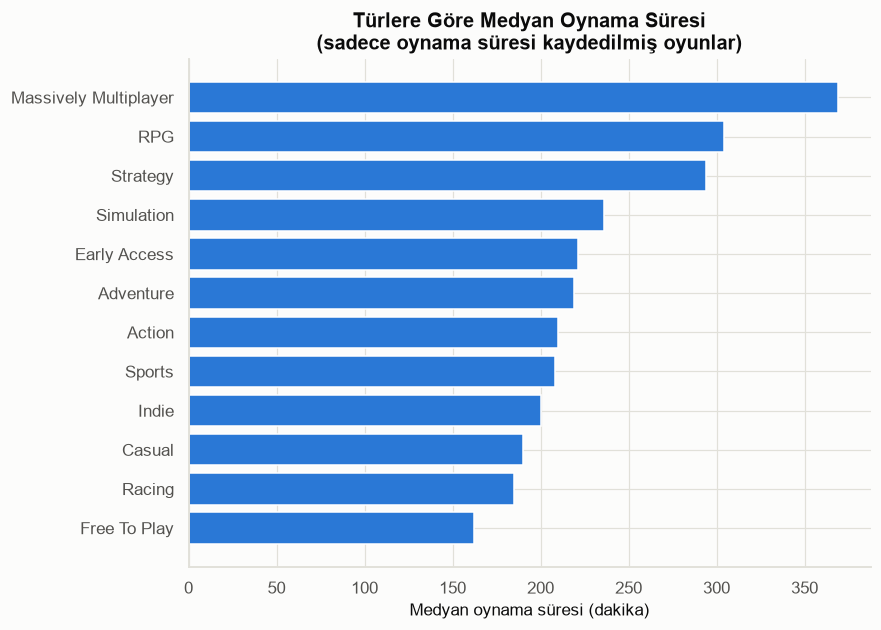

In [8]:
genre_encoded_full, top12_genres = multi_hot_encode(df, 'genres', top_n=12)
rows = []
for g in top12_genres:
    mask = df['genres'].apply(lambda lst: g in lst)
    sub = df.loc[mask & (df['average_playtime_forever'] > 0), 'average_playtime_forever']
    rows.append({'tur': g, 'medyan_oynama_suresi_dk': sub.median()})
playtime_by_genre = pd.DataFrame(rows).set_index('tur').sort_values('medyan_oynama_suresi_dk')

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(playtime_by_genre.index, playtime_by_genre['medyan_oynama_suresi_dk'], color=CATEGORICAL_PALETTE[0])
ax.set_title('Türlere Göre Medyan Oynama Süresi\n(sadece oynama süresi kaydedilmiş oyunlar)')
ax.set_xlabel('Medyan oynama süresi (dakika)')
save_fig(fig, '04_06_turlere_gore_oynama_suresi')
plt.show()

RPG ve Strategy oyunları en uzun medyan oynama süresine sahip — bu türlerin doğası
gereği (ilerleme sistemleri, uzun kampanyalar) beklenen bir sonuç. Casual ve Indie ise en kısa
oynama sürelerinde; bu, bu türlerdeki oyunların çoğunlukla kısa/bağımsız deneyimler sunduğunu
gösteriyor. **Not:** Oyunların sadece %42'sinde oynama süresi verisi mevcut (Steam gizlilik
ayarlarına bağlı); bu karşılaştırma sadece verisi olan oyunlar üzerinden yapıldı.

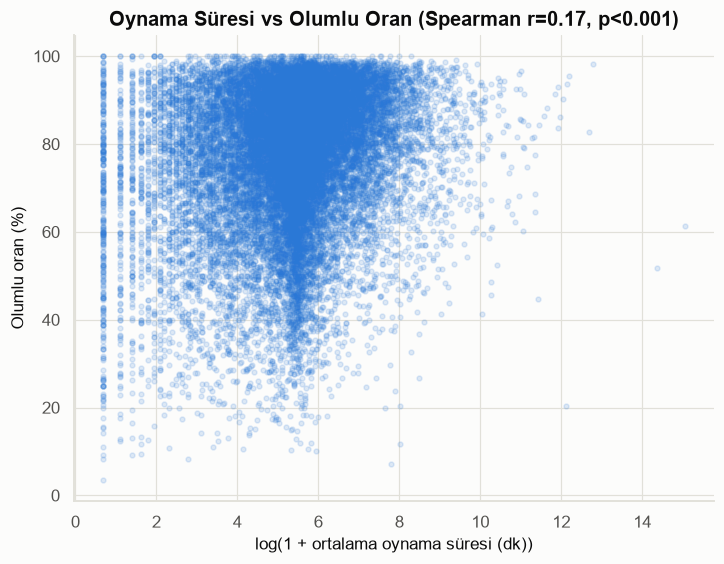

In [9]:
has_playtime = enough[enough['average_playtime_forever'] > 0]
corr, p = spearmanr(has_playtime['average_playtime_forever'], has_playtime['positive_ratio'])

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(np.log1p(has_playtime['average_playtime_forever']), has_playtime['positive_ratio'] * 100,
           alpha=0.15, s=10, color=CATEGORICAL_PALETTE[0])
ax.set_title(f'Oynama Süresi vs Olumlu Oran (Spearman r={corr:.2f}, p<0.001)')
ax.set_xlabel('log(1 + ortalama oynama süresi (dk))')
ax.set_ylabel('Olumlu oran (%)')
save_fig(fig, '04_07_oynama_suresi_vs_pozitif_oran')
plt.show()

Oynama süresi ile olumlu oran arasında zayıf-orta düzeyde pozitif bir ilişki var
(r≈0.17) — insanların daha uzun oynadığı oyunları biraz daha olumlu değerlendirme eğiliminde
olması mantıklı (ilgi çekmeseydi bırakırlardı), ama ilişki çok güçlü değil; kısa ama yoğun/iyi
tasarlanmış oyunlar da yüksek puan alabiliyor.

## 4.6 Metin Analizi (Opsiyonel)

İndie oyunların açıklama metinlerinde (`about_the_game`) **TF-IDF** ile başarılı
(`review_label` ∈ {Very Positive, Overwhelmingly Positive}) ve başarısız
(`review_label` ∈ {Mixed, Negative, Overwhelmingly Negative}) oyunları ayırt eden kelimeleri
karşılaştırıyoruz.

Başarılı: 22,105 | Başarısız: 11,300


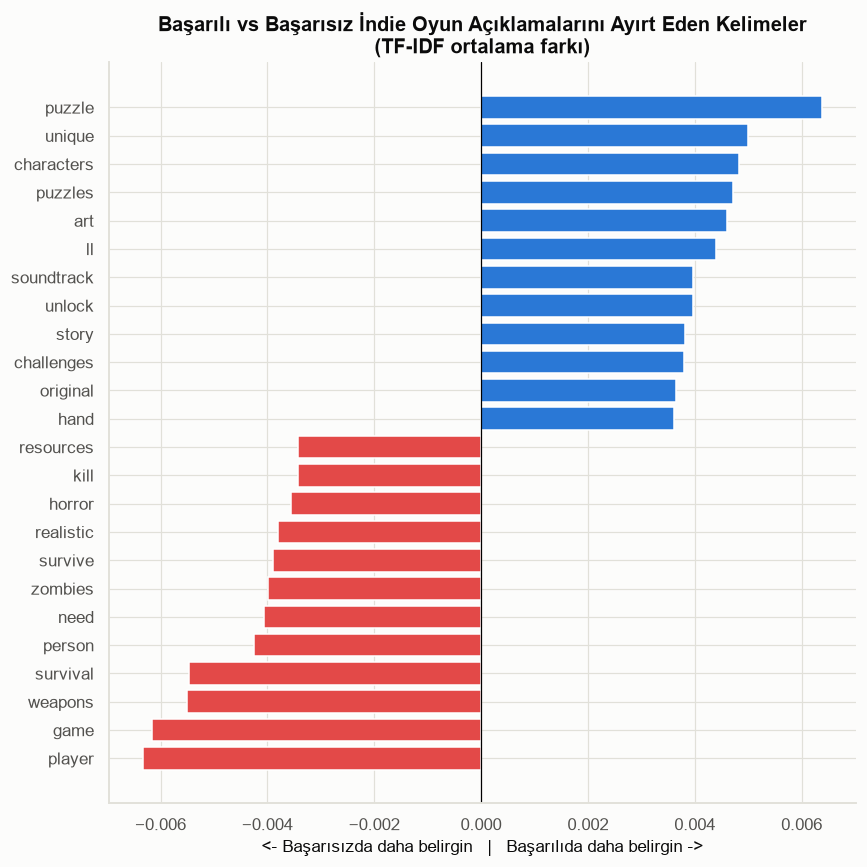

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

text_df = indie[indie['about_the_game'].str.len() > 20]
basarili = text_df[text_df['review_label'].isin(['Very Positive', 'Overwhelmingly Positive'])]
basarisiz = text_df[text_df['review_label'].isin(['Mixed', 'Negative', 'Overwhelmingly Negative'])]
print(f"Başarılı: {len(basarili):,} | Başarısız: {len(basarisiz):,}")

vectorizer = TfidfVectorizer(max_features=3000, stop_words='english', min_df=10)
tfidf = vectorizer.fit_transform(pd.concat([basarili['about_the_game'], basarisiz['about_the_game']]))

n_basarili = len(basarili)
mean_basarili = np.asarray(tfidf[:n_basarili].mean(axis=0)).ravel()
mean_basarisiz = np.asarray(tfidf[n_basarili:].mean(axis=0)).ravel()
diff = mean_basarili - mean_basarisiz
vocab = np.array(vectorizer.get_feature_names_out())

top_n = 12
pos_idx = np.argsort(diff)[-top_n:]
neg_idx = np.argsort(diff)[:top_n]
words = np.concatenate([vocab[neg_idx], vocab[pos_idx]])
values = np.concatenate([diff[neg_idx], diff[pos_idx]])
colors = [CATEGORICAL_PALETTE[7] if v < 0 else CATEGORICAL_PALETTE[0] for v in values]

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(words, values, color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Başarılı vs Başarısız İndie Oyun Açıklamalarını Ayırt Eden Kelimeler\n(TF-IDF ortalama farkı)')
ax.set_xlabel('<- Başarısızda daha belirgin   |   Başarılıda daha belirgin ->')
fig.tight_layout()
save_fig(fig, '04_08_basarili_vs_basarisiz_kelimeler')
plt.show()

Başarılı indie oyunların açıklamalarında **"puzzle", "unique", "characters", "story",
"soundtrack", "art", "cute"** gibi özgünlük ve zanaatkarlığı (craft) vurgulayan kelimeler öne
çıkıyor. Başarısız oyunlarda ise **"survival", "zombie", "weapons", "realistic", "open",
"resources"** gibi — doygun, jenerik "survival/crafting" alt türüne işaret eden kelimeler
baskın. **Bu bulgu tamamen korelasyoneldir** ve küçük bir kelime kümesine dayanır, ama Faz
3/4'teki diğer bulgularla tutarlı bir hikâye anlatıyor: aşırı doymuş, jenerik temalardan
kaçınıp özgün bir sanat yönü/hikâye sunmak başarı ile ilişkili görünüyor.

## Faz 4 Özeti

- **Kalite ve popülerlik farklı başarı biçimleri:** oyunların sadece %8,7'si hem yüksek kaliteli
  hem yüksek popüler; %9,3'ü kaliteli ama dar kitleli "gizli cevher".
- İndie payı 2016 civarında zirve yapıp hafifçe geriledi ama hâlâ Steam'in çoğunluğunu oluşturuyor.
- Başarılı (üst %10) indie oyunlar belirgin şekilde **daha fazla dil** ve **daha fazla başarım**
  içeriyor — nispeten düşük maliyetli, yüksek potansiyel etkili yatırımlar.
- **Fırsat haritası:** "Multiplayer" ve "Anime" etiketleri görece az rekabetle yüksek talep
  gösteriyor; "Simulation"/"Atmospheric" ise doymuş ve göreceli düşük talepte.
- İstatistiksel testler: ücretsiz/indie/self-published farkları **anlamlı ama etki büyüklüğü
  küçük** — tek bir faktör başarıyı belirlemiyor, bu da Faz 5 modellemesinin motivasyonu.
- Fiyat-kalite ilişkisi hafif ters-U şeklinde, \$5-10 aralığı en yüksek medyan kaliteye sahip.
- Oynama süresi ile kalite arasında zayıf-orta pozitif ilişki (r≈0.17); RPG/Strategy en uzun
  oynama sürelerine sahip.
- Metin analizi: başarılı oyunlar özgünlük/sanat/hikâye vurgusu yaparken, başarısızlar doymuş
  "survival/zombie" temasına yöneliyor (korelasyonel bir gözlem, nedensellik iddiası değil).